# Device-aware weighted Gerchberg-Saxton

**Question:** Can the weighted Gerchberg-Saxton loop absorb pixel crosstalk and the other limits of the SLM inside its iterations, instead of fighting them after, and by how much does it beat the strongest baseline on a device that has them?

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 02 and 03 of this topic and notebook 01 of topic 01
- **Reading time:** about 60 minutes

## Objectives

Every method of the notebooks so far computes a hologram for an ideal SLM and trusts the result. A real SLM quantizes the phase, blurs it between neighbouring pixels (the crosstalk of the liquid crystal), has a fill factor below 1 and flickers. The standard answer is a camera in the loop, which corrects the traps after the fact. The component BS-1 of the product asks a different question: put the device model inside the weighted loop, so that the hologram is computed for the device. You will first see how wrong an ideal-model method is about its own result on the device of case C08, then run the best methods the literature offers, phase-fixed weighted Gerchberg-Saxton and conjugate gradient through the crosstalk operator, and then the product's B1, two seeds each, scored on the device. The last measurement finds where B1's advantage lives and where it costs.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import device_of, setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.device import device_focal_field
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b1_device_wgs
from pipeline.model.holo.methods.optim import m13_crosstalk_cg

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def on_device(phi, setup, traps, device):
    """Efficiency, uniformity and spread (percent) of a hologram as the device shows it, mean of four flicker draws."""
    rows = []
    for draw in range(4):
        field = device_focal_field(phi, setup, device, Rng(draw))
        i = metrics.trap_intensities(forward.trap_fields_from_fft(field, setup, traps))
        rows.append((metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)))
    return np.mean(rows, axis=0)

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence; the crosstalk parameters are those fitted by Schroff et al. 2023 (https://doi.org/10.1038/s41598-023-30296-6).
- File read: `data/examples/cases.json`, case C08: 64 traps on a 128 by 128 pixel SLM with 4 phase bits, crosstalk of fitted width 1.24 and exponent 1.8, a fill factor of 0.85 and a flicker of 0.05 rad, and two seeds counted up from the case seed.

In [2]:
# case C08: 64 traps on a 128 x 128 pixel SLM with 4 bits, pixel crosstalk, a fill factor of 0.85 and a little flicker
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C08_device_limited"]
setup = setup_of(rec)
device = device_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(rec["budget"]["iterations"])
seeds = [rec["seed"], rec["seed"] + 1]
print(f"{len(traps)} traps, {setup.n_pix} x {setup.n_pix} pixels, {device.bit_depth} bits,")
print(f"crosstalk (sigma, q): {device.crosstalk}")
print(f"fill factor {device.fill_factor}, flicker {device.flicker_rad} rad")

64 traps, 128 x 128 pixels, 4 bits,
crosstalk (sigma, q): (1.24, 1.8)
fill factor 0.85, flicker 0.05 rad


## Method

The device model of the product acts on the displayed phase in four steps: quantization to $2^b$ levels, a response curve, flicker noise, and the crosstalk, a circular convolution of the upsampled phase with a kernel whose transfer function is $\exp[-(|k_x|^q + |k_y|^q)/\sigma^q]$, followed by the pixel aperture (Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6). A hologram is judged by the focal field of that displayed phase. The methods of the earlier notebooks do not know the device: phase-fixed weighted Gerchberg-Saxton (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) iterates the ideal model and stops when it is uniform on the ideal model. The metrics are those of topic 01, computed on the device and averaged over four draws of the flicker, because the flicker is random and a hologram must be good on the average device.

The first cell runs weighted Gerchberg-Saxton (M06) and phase-fixed weighted Gerchberg-Saxton (M07) for the 30 iterations of the case and prints two readings of the same hologram: the spread that the method sees on the ideal model, which is the last entry of its history, and the spread that the device shows.

In [3]:
# the ideal model against the device: weighted GS and phase-fixed WGS judge themselves on the ideal model
ideal_runs = {}
for name, method in (("M06", m06_gsw), ("M07", m07_phase_fixed_wgs)):
    ideal_runs[name] = method.run(setup, target, budget=budget, rng=Rng(seeds[0]))
    last = ideal_runs[name].history[-1]
    shown = on_device(ideal_runs[name].phi, setup, traps, device)
    print(f"{name}: own judgement on the ideal model: sigma = {last['rel_std']:.3f} %, e = {last['efficiency']:.4f}")
    print(f"     on the device: sigma = {shown[2]:.3f} %, e = {shown[0]:.4f}")

M06: own judgement on the ideal model: sigma = 1.262 %, e = 0.8018
     on the device: sigma = 14.424 %, e = 0.6812
M07: own judgement on the ideal model: sigma = 0.005 %, e = 0.7958
     on the device: sigma = 13.349 %, e = 0.6761


A natural reply is that the method has not iterated enough. The cell runs M07 for 100 iterations and reads it on the device next to the 30 iteration hologram.

In [4]:
# more iterations of the ideal-model method do not help: 100 iterations of phase-fixed WGS, read on the device
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(100), rng=Rng(seeds[0]))
for label, res in (("30", ideal_runs["M07"]), ("100", long_run)):
    shown = on_device(res.phi, setup, traps, device)
    print(f"M07 {label:>3s} iterations: on the device: sigma = {shown[2]:.3f} %")
    print(f"     u = {shown[1]:.4f}, e = {shown[0]:.4f}")

M07  30 iterations: on the device: sigma = 13.349 %
     u = 0.6922, e = 0.6761
M07 100 iterations: on the device: sigma = 13.349 %
     u = 0.6922, e = 0.6761


## State of the art

Two lines of work answer the gap. The first is camera feedback, which corrects the traps after the hologram is made and which the product emulates in notebooks of the later topics. The second puts the crosstalk model inside the optimization: Schroff et al. (2023) use it with conjugate gradient on shaped potentials, and the product's M13 is that method for the traps of this case, with the gradient through the adjoint of the crosstalk operator in closed form. It is the strongest baseline for a device with crosstalk, since it optimizes the device-aware intensity directly, at the price of many iterations; the strongest baseline for the ideal model is phase-fixed weighted Gerchberg-Saxton. The cell runs M13 on the device and prints the spread, the uniformity and the efficiency on the device.

B1 does not start cold: it first runs 12 iterations of ideal-model weighted Gerchberg-Saxton (M06) from the random superposition of its seed, and then 4 outer iterations of 3 conjugate-gradient steps. A fair test of the strongest baseline gives M13 the same start and the same number of conjugate-gradient steps: the cell computes that start with M06 (12 iterations, the same seed, so the same phase B1 starts from), runs M13 for 12 iterations from it with the device of the case, and reads the result on the device. It also runs M13 for 12 iterations from its own random start, to show what the start is worth to the conjugate gradient. A run of M13 to convergence takes about a hundred iterations and several minutes, so the equal budget is the comparison this notebook makes.

In [5]:
# the other way to use the device model: conjugate gradient through the crosstalk operator (M13), 12 iterations,
# from B1's own start (12 iterations of weighted GS, same seed) and, for contrast, from its own random start
warm_start = m06_gsw.run(setup, target, budget=Budget(12), rng=Rng(seeds[0])).phi
cg_run = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(seeds[0]), init=warm_start)
cg_numbers = on_device(cg_run.phi, setup, traps, device)
cold_run = m13_crosstalk_cg.run(setup, target, device=device, budget=Budget(12), rng=Rng(seeds[0]))
cg_cold = on_device(cold_run.phi, setup, traps, device)
for label, row in (("from B1's start", cg_numbers), ("from a random start", cg_cold)):
    print(f"M13 12 iterations {label}: on the device: sigma = {row[2]:.3f} %, u = {row[1]:.4f}, e = {row[0]:.4f}")


M13 12 iterations from B1's start: on the device: sigma = 8.349 %, u = 0.8211, e = 0.6712
M13 12 iterations from a random start: on the device: sigma = 57.314 %, u = 0.0054, e = 0.2001


## Beyond the state of the art

The claim BS-1 of the product: keep the weights of weighted Gerchberg-Saxton, $w_m \leftarrow w_m\langle r\rangle/r_m$, with $r_m$ measured on the device's focal field, and replace the phase update by a few conjugate-gradient steps on the device-aware intensity loss, through the straight-through quantizer and the crosstalk operator. The weights give the loop its memory, and the gradient steps give it the device. The gap it fills is that the crosstalk model had been used only with conjugate gradient on shaped potentials, never inside a weighted loop for trap arrays (Schroff et al. 2023). The component is B1 in the code. The tests that follow are the ones that can refute it: two seeds against phase-fixed weighted Gerchberg-Saxton, one seed against the conjugate gradient with the device from the same start and with the same number of gradient steps, and a sweep of the crosstalk strength to see where the advantage comes from and what it costs.

The cell runs B1, with 4 outer iterations of 3 conjugate-gradient steps each, for the two seeds, and M07 for the same seeds, reads both on the device, and prints the mean, the range of the spread and the ratios.

In [6]:
# the claim, BS-1: weighted GS whose phase update is a few conjugate-gradient steps through the device model
b1_runs = [b1_device_wgs.run(setup, target, device=device, budget=Budget(4), rng=Rng(s)) for s in seeds]
b1_numbers = np.array([on_device(r.phi, setup, traps, device) for r in b1_runs])
m07_runs = [m07_phase_fixed_wgs.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
m07_numbers = np.array([on_device(r.phi, setup, traps, device) for r in m07_runs])
for name, rows in (("M07", m07_numbers), ("B1", b1_numbers)):
    e, u, sigma = rows.mean(axis=0)
    low, high = rows[:, 2].min(), rows[:, 2].max()
    print(f"{name}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.3f} % (range {low:.3f} to {high:.3f})")
ratio = m07_numbers[:, 2].mean() / b1_numbers[:, 2].mean()
print(f"spread of M07 over the spread of B1: {ratio:.1f}")
print(f"efficiency of B1 over that of M07: {b1_numbers[:, 0].mean() / m07_numbers[:, 0].mean():.3f}")
print(f"spread of M13 (same start, same steps) over that of B1, first seed: {cg_numbers[2] / b1_numbers[0, 2]:.2f}")
print(f"efficiency of B1 over that of M13 on the first seed: {b1_numbers[0, 0] / cg_numbers[0]:.3f}")

M07: e = 0.6785, u = 0.7086, sigma = 13.132 % (range 12.915 to 13.349)
B1: e = 0.6538, u = 0.8692, sigma = 6.086 % (range 5.449 to 6.723)
spread of M07 over the spread of B1: 2.2
efficiency of B1 over that of M07: 0.964
spread of M13 (same start, same steps) over that of B1, first seed: 1.24
efficiency of B1 over that of M13 on the first seed: 0.974


Crosstalk is only one of the limits of the device. The cell keeps the 4 bits, the fill factor and the flicker and changes only the crosstalk, from none to a width of 0.8 (strong; a smaller width means more blur), running B1 and reading M07 on each device for the first seed.

In [7]:
# where does the advantage live? the crosstalk strength from none to strong, first seed, same bits and fill factor
rows = {}
levels = (("none", None), ("1.24", (1.24, 1.8)), ("0.8", (0.8, 1.8)))
for label, crosstalk in levels:
    dev = replace(device, crosstalk=crosstalk)
    ours = b1_runs[0]
    if label != "1.24":
        ours = b1_device_wgs.run(setup, target, device=dev, budget=Budget(4), rng=Rng(seeds[0]))
    rows[label] = (on_device(m07_runs[0].phi, setup, traps, dev), on_device(ours.phi, setup, traps, dev))
    m07_row, b1_row = rows[label]
    factor = m07_row[2] / b1_row[2]
    print(f"{label:>5s}: M07 sigma = {m07_row[2]:7.3f} %, B1 sigma = {b1_row[2]:7.3f} %, ratio {factor:.2f}")
    print(f"       M07 e = {m07_row[0]:.4f}, B1 e = {b1_row[0]:.4f}")

 none: M07 sigma =   3.953 %, B1 sigma =   0.757 %, ratio 5.22
       M07 e = 0.7418, B1 e = 0.7405
 1.24: M07 sigma =  13.349 %, B1 sigma =   6.723 %, ratio 1.99
       M07 e = 0.6761, B1 e = 0.6541
  0.8: M07 sigma =  24.540 %, B1 sigma =  16.092 %, ratio 1.53
       M07 e = 0.6235, B1 e = 0.5295


The first figure plots the relative spread of the traps on the device of C08 for five runs: the mean of two seeds for M07 and B1, and the first seed for M06 and for M13 from the two starts.

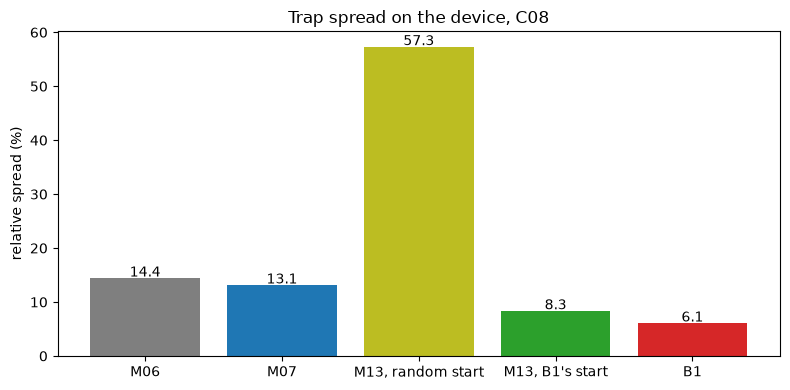

In [8]:
# the spread of the traps on the device: mean of two seeds for M07 and B1, the first seed for M06 and M13
fig, ax = plt.subplots(figsize=(8, 4))
bars = {
    "M06": on_device(ideal_runs["M06"].phi, setup, traps, device)[2],
    "M07": m07_numbers[:, 2].mean(),
    "M13, random start": cg_cold[2],
    "M13, B1's start": cg_numbers[2],
    "B1": b1_numbers[:, 2].mean(),
}
ax.bar(list(bars), list(bars.values()), color=["C7", "C0", "C8", "C2", "C3"])
for k, value in enumerate(bars.values()):
    ax.text(k, value + 0.3, f"{value:.1f}", ha="center")
ax.set_ylabel("relative spread (%)")
ax.set_title("Trap spread on the device, C08")
fig.tight_layout()
plt.show()


The bars fall in the order of how much of the device each method knows. M06, which knows none of it, has a spread of 14.4 percent and M07, which converges on the ideal model, 13.1 percent on the mean of two seeds; both judged themselves on the ideal model at 1.262 and 0.005 percent, and a hundred iterations did not change a digit of M07's result on the device. M13, the conjugate gradient through the crosstalk operator, depends on its start: from its own random start 12 iterations leave it at 57.3 percent, an unconverged run, and from the start B1 uses, 12 iterations of weighted GS, the same 12 gradient steps bring it to 8.3 percent. B1, which has the device inside the weighted loop, ends at 6.1 percent. The figure does not show the efficiency each method pays, which the table above prints.

The second figure has two panels. On the left, the ratio of the spread of M07 to that of B1 against the crosstalk width, from no crosstalk to the strongest. On the right, the efficiency of both.

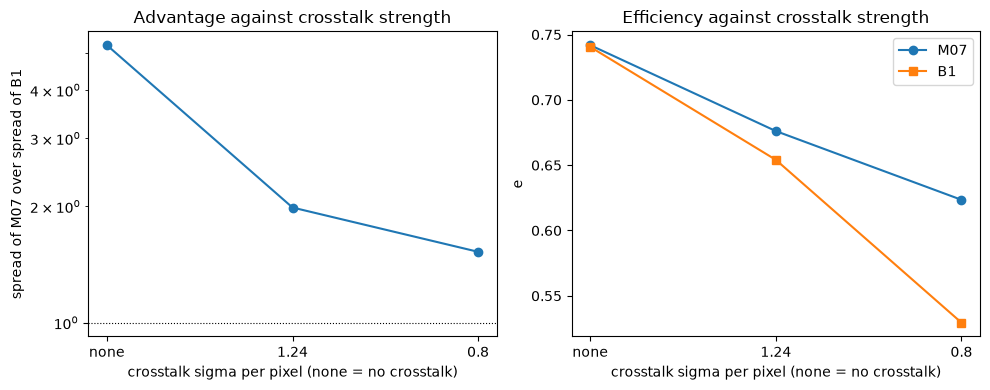

In [9]:
# the ratio of the two spreads against the crosstalk strength, and the efficiency each method keeps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
labels = list(rows)
ax1.semilogy(labels, [rows[k][0][2] / rows[k][1][2] for k in labels], "o-")
ax1.axhline(1.0, color="k", lw=0.8, ls=":")
ax1.set_xlabel("crosstalk sigma per pixel (none = no crosstalk)")
ax1.set_ylabel("spread of M07 over spread of B1")
ax1.set_title("Advantage against crosstalk strength")
ax2.plot(labels, [rows[k][0][0] for k in labels], "o-", label="M07")
ax2.plot(labels, [rows[k][1][0] for k in labels], "s-", label="B1")
ax2.set_xlabel("crosstalk sigma per pixel (none = no crosstalk)")
ax2.set_ylabel("e")
ax2.set_title("Efficiency against crosstalk strength")
ax2.legend()
fig.tight_layout()
plt.show()

The advantage is not a crosstalk effect alone. Without any crosstalk, with only 4 bits, a fill factor of 0.85 and flicker, M07 has a spread of 3.953 percent and B1 0.757, a ratio of 5.22, because B1 sees the quantizer and the aperture too. As crosstalk grows both get worse and the ratio falls: 1.99 at the case's width of 1.24, and 1.53 at 0.8, where B1 still has 16.092 percent against 24.540. The right panel shows the price. Without crosstalk the two efficiencies are equal to the third digit (0.7405 against 0.7418); at 1.24 B1 has 0.6541 against 0.6761, and at 0.8 it has 0.5295 against 0.6235, so with strong crosstalk B1 spends power on being uniform. The sweep uses one seed per point and one fixed number of steps, and it says nothing about devices with a different bit depth.

## Results

**Answer:** Yes, against both baselines on this device, by a factor that depends on which. On the device of C08 the ideal-model methods are wrong about themselves: phase-fixed weighted Gerchberg-Saxton judges its own hologram at a spread of 0.005 percent and the device shows 13.349 percent, and 100 iterations instead of 30 change nothing. B1, with 4 outer iterations of 3 conjugate-gradient steps after 12 iterations of weighted GS, reaches 6.086 percent on average over two seeds (5.449 to 6.723), against 13.132 percent for M07 (12.915 to 13.349), a factor of 2.2 at 0.964 of M07's efficiency; the uniformity is 0.8692 against 0.7086. The strongest baseline, the conjugate gradient through the crosstalk operator (M13), given the same start and the same 12 gradient steps, reaches 8.349 percent with an efficiency of 0.6712 on the first seed, where B1 has 6.723 percent: B1's spread is lower by a factor of 1.24, at 0.974 of M13's efficiency. From its own random start M13 ends at 57.314 percent after those 12 steps, so the start is most of what the conjugate gradient needs. The advantage over M07 depends on the device: 5.22 times with no crosstalk, 1.99 at the crosstalk of the case, 1.53 at a width of 0.8, where B1 gives up efficiency (0.5295 against 0.6235). BS-1 holds on this device against phase-fixed weighted Gerchberg-Saxton by a factor of two and against the device-aware conjugate gradient by a quarter, on two seeds and one seed respectively.

## Summary

A hologram computed for an ideal SLM is wrong about itself by orders of magnitude on a device with 4 bits and crosstalk, and more iterations do not repair it. Putting the device in the loop inside the weighted iteration, as B1 does, halves the spread against the ideal-model state of the art at a cost of a few percent of the efficiency, a cost that grows when the crosstalk is strong, and it beats the device-aware conjugate gradient from the same start and with the same number of gradient steps by a smaller margin. What is not tested is the comparison with a conjugate gradient run to convergence, a different bit depth or fill factor, flicker in the loop, and more than two seeds.

## References

- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.
- Kim, Kim, Lee and Ahn, "Gerchberg-Saxton algorithm with phase fixing for tweezer arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.